In [1]:
import os
from pathlib import Path

In [2]:
# Main project directory
PROJECT = Path.cwd() / "PacketScope"

# Create folders
folders = [
    "data",
    "notebooks",
    "visualizations",
    "reports"
]

PROJECT.mkdir(exist_ok=True)

for folder in folders:
    (PROJECT / folder).mkdir(exist_ok=True)

print("Project folders created successfully!")
print(PROJECT)

Project folders created successfully!
C:\Project_5\PacketScope


In [3]:
files = [
    "README.md",
    "requirements.txt",
    "data/packets.csv",
    "data/tcp_packets.csv",
    "data/udp_packets.csv",
    "reports/project_summary.txt"
]

for file in files:
    file_path = PROJECT / file
    file_path.parent.mkdir(parents=True, exist_ok=True)
    file_path.touch(exist_ok=True)

print("Project files created successfully!")

Project files created successfully!


In [4]:
def show_structure(path, indent=""):
    items = sorted(path.iterdir())

    for index, item in enumerate(items):
        is_last = index == len(items) - 1
        print(indent + ("└── " if is_last else "├── ") + item.name)

        if item.is_dir():
            show_structure(
                item,
                indent + ("    " if is_last else "│   ")
            )

print(PROJECT.name)
show_structure(PROJECT)

PacketScope
├── data
│   ├── packets.csv
│   ├── tcp_packets.csv
│   └── udp_packets.csv
├── notebooks
├── README.md
├── reports
│   └── project_summary.txt
├── requirements.txt
└── visualizations


In [5]:
requirements = """
scapy
pandas
matplotlib
seaborn
plotly
jupyter
"""

(PROJECT / "requirements.txt").write_text(
    requirements.strip(),
    encoding="utf-8"
)

print("Dependencies saved!")

Dependencies saved!


In [6]:
from scapy.all import sniff, IP, TCP, UDP

print("Scapy imported successfully!")

Scapy imported successfully!


In [7]:
from scapy.all import conf

print("Scapy configuration:")
print(conf.use_pcap)
print(conf.ifaces)

Scapy configuration:
False
Source   Index  Name                             MAC                    IPv4            IPv6                           
libpcap  1      Software Loopback Interface 1                           127.0.0.1       ::1                            
libpcap  10     Microsoft Kernel Debug Network_                                                                        
libpcap  11     Microsoft Teredo Tunneling Ada_                                                                        
libpcap  12     WAN Miniport (Network Monitor)                                                                         
libpcap  13     Realtek PCIe GBE Family Contro_  LCFCElectron:e7:a6:26  169.254.200.51  fe80::da8b:a7c:5407:eb45       
libpcap  14     WAN Miniport (IP)                                                                                      
libpcap  15     WAN Miniport (SSTP)                                                                                    
libpcap  16  

In [8]:
from scapy.all import sniff

packets = sniff(
    count=10,
    timeout=20
)

print("Captured packets:", len(packets))

RuntimeError: Sniffing and sending packets is not available at layer 2: winpcap is not installed. You may use conf.L3socket or conf.L3socket6 to access layer 3

In [9]:
from scapy.all import conf

print("PCAP enabled:", conf.use_pcap)
print("\nAvailable interfaces:")
print(conf.ifaces)

PCAP enabled: False

Available interfaces:
Source   Index  Name                             MAC                    IPv4            IPv6                           
libpcap  1      Software Loopback Interface 1                           127.0.0.1       ::1                            
libpcap  10     Microsoft Kernel Debug Network_                                                                        
libpcap  11     Microsoft Teredo Tunneling Ada_                                                                        
libpcap  12     WAN Miniport (Network Monitor)                                                                         
libpcap  13     Realtek PCIe GBE Family Contro_  LCFCElectron:e7:a6:26  169.254.200.51  fe80::da8b:a7c:5407:eb45       
libpcap  14     WAN Miniport (IP)                                                                                      
libpcap  15     WAN Miniport (SSTP)                                                                                  

In [10]:
from scapy.all import conf

conf.use_pcap = True

print("PCAP enabled:", conf.use_pcap)

PCAP enabled: False


In [11]:
import scapy
import sys

print("Python:", sys.executable)
print("Scapy version:", scapy.__version__)
print("Python version:", sys.version)

Python: C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\python.exe
Scapy version: 2.8.0
Python version: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]


In [12]:
import os

paths = [
    r"C:\Windows\System32\Npcap",
    r"C:\Windows\System32\wpcap.dll",
    r"C:\Windows\System32\Packet.dll"
]

for path in paths:
    print(path, "EXISTS:", os.path.exists(path))

C:\Windows\System32\Npcap EXISTS: True
C:\Windows\System32\wpcap.dll EXISTS: True
C:\Windows\System32\Packet.dll EXISTS: True


In [13]:
import platform

print("Architecture:", platform.architecture())
print("Machine:", platform.machine())

Architecture: ('64bit', 'WindowsPE')
Machine: AMD64


In [14]:
import ctypes

dll_paths = [
    r"C:\Windows\System32\Npcap\wpcap.dll",
    r"C:\Windows\System32\Npcap\Packet.dll"
]

for path in dll_paths:
    try:
        dll = ctypes.WinDLL(path)
        print("SUCCESS:", path)
    except Exception as e:
        print("FAILED:", path)
        print(e)

SUCCESS: C:\Windows\System32\Npcap\wpcap.dll
SUCCESS: C:\Windows\System32\Npcap\Packet.dll


In [15]:
import os

print("PATH environment variable:")
print(os.environ["PATH"])

print("\nNpcap directory:")
print(os.listdir(r"C:\Windows\System32\Npcap"))

PATH environment variable:
C:\Program Files\Common Files\Oracle\Java\javapath;C:\Windows\system32;C:\Windows;C:\Windows\System32\Wbem;C:\Windows\System32\WindowsPowerShell\v1.0\;C:\Windows\System32\OpenSSH\;C:\Program Files\dotnet\;C:\Program Files\Git\cmd;C:\Program Files\nodejs\;C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Scripts\;C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\;C:\Users\Lenovo\AppData\Local\Programs\Python\Launcher\;C:\Users\Lenovo\.local\bin;C:\Users\Lenovo\AppData\Local\Microsoft\WindowsApps;C:\Program Files\JetBrains\IntelliJ IDEA Community Edition 2023.1.2\bin;;C:\Users\Lenovo\AppData\Local\Programs\Microsoft VS Code\bin;C:\Users\Lenovo\.dotnet\tools;C:\Users\Lenovo\AppData\Local\Python\bin;C:\Users\Lenovo\AppData\Roaming\Microsoft\Windows\Start Menu\Programs\Python\Python 3.15;C:\Users\Lenovo\AppData\Roaming\npm

Npcap directory:
['NpcapHelper.exe', 'Packet.dll', 'WlanHelper.exe', 'wpcap.dll']


In [16]:
from scapy.all import conf

print("use_pcap:", conf.use_pcap)
print("PCAP provider:", conf.pcapdnet)
print("Network interfaces:", len(conf.ifaces))

use_pcap: False


AttributeError: 'Conf' object has no attribute 'pcapdnet'

In [18]:
import os
import ctypes
import ctypes.util

npcap_path = r"C:\Windows\System32\Npcap"

# Add Npcap to the current Python process
os.environ["PATH"] = npcap_path + ";" + os.environ["PATH"]

# Register DLL search directory
dll_directory = os.add_dll_directory(npcap_path)

print("wpcap discovery:", ctypes.util.find_library("wpcap"))
print("Npcap DLL directory registered!")

wpcap discovery: C:\Windows\System32\Npcap\wpcap.dll
Npcap DLL directory registered!


In [19]:
from scapy.all import sniff

packets = sniff(
    iface=conf.ifaces.dev_from_index(4),
    count=10,
    timeout=20
)

print("Captured packets:", len(packets))

RuntimeError: Sniffing and sending packets is not available at layer 2: winpcap is not installed. You may use conf.L3socket or conf.L3socket6 to access layer 3

In [1]:
from scapy.all import conf

conf.use_pcap = True

print("PCAP status:", conf.use_pcap)
print("Layer 2 listener:", conf.L2listen)
print("Layer 2 socket:", conf.L2socket)

PCAP status: True
Layer 2 listener: <L2pcapListenSocket: read packets at layer 2 using libpcap>
Layer 2 socket: <L2pcapSocket: read/write packets at layer 2 using only libpcap>


In [2]:
from scapy.all import sniff, conf

wifi = conf.ifaces.dev_from_index(4)

print("Capturing packets from Wi-Fi...")

packets = sniff(
    iface=wifi,
    count=10,
    timeout=20,
    store=True
)

print("Successfully captured:", len(packets))

Capturing packets from Wi-Fi...
Successfully captured: 10


In [3]:
for i, packet in enumerate(packets, start=1):
    print(f"\nPACKET {i}")
    packet.summary()


PACKET 1

PACKET 2

PACKET 3

PACKET 4

PACKET 5

PACKET 6

PACKET 7

PACKET 8

PACKET 9

PACKET 10


In [4]:
from scapy.all import IP, TCP, UDP

for packet in packets:

    if IP not in packet:
        continue

    if TCP in packet:
        print("TCP:", packet[IP].src, "→", packet[IP].dst)

    elif UDP in packet:
        print("UDP:", packet[IP].src, "→", packet[IP].dst)

In [5]:
for i, packet in enumerate(packets, start=1):
    print(f"\n========== PACKET {i} ==========")
    packet.show()


========== PACKET 1 ==========
###[ Ethernet ]###
  dst       = 00:db:df:a9:91:c9
  src       = 04:75:f9:09:87:30
  type      = VLAN
###[ 802.1Q ]###
     prio      = 0
     dei       = 0
     vlan      = 0
     type      = IPv6
###[ IPv6 ]###
        version   = 6
        tc        = 64
        fl        = 884906
        plen      = 32
        nh        = UDP
        hlim      = 49
        src       = 2600:140f:7200:3c::17d4:d6
        dst       = 2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d
###[ UDP ]###
           sport     = https
           dport     = 49810
           len       = 32
           chksum    = 0x6c3f
###[ Raw ]###
              load      = b'N{>B\xe4m\xa6\xea\x11Y\xd6 \x95&\xafaqD\xb1\xeb\xa1\x01\x10-'


========== PACKET 2 ==========
###[ Ethernet ]###
  dst       = 04:75:f9:09:87:30
  src       = 00:db:df:a9:91:c9
  type      = IPv6
###[ IPv6 ]###
     version   = 6
     tc        = 0
     fl        = 674677
     plen      = 21
     nh        = TCP
     hlim      = 64
 

In [6]:
from scapy.all import IP, TCP, UDP

for i, packet in enumerate(packets, start=1):

    if IP in packet:
        ip = packet[IP]

        if TCP in packet:
            protocol = "TCP"
        elif UDP in packet:
            protocol = "UDP"
        else:
            protocol = "OTHER"

        print(
            f"Packet {i}: {protocol} | "
            f"{ip.src} → {ip.dst}"
        )
    else:
        print(f"Packet {i}: Non-IP packet")

Packet 1: Non-IP packet
Packet 2: Non-IP packet
Packet 3: Non-IP packet
Packet 4: Non-IP packet
Packet 5: Non-IP packet
Packet 6: Non-IP packet
Packet 7: Non-IP packet
Packet 8: Non-IP packet
Packet 9: Non-IP packet
Packet 10: Non-IP packet


In [7]:
print("Total captured:", len(packets))
print("TCP:", sum(TCP in p for p in packets))
print("UDP:", sum(UDP in p for p in packets))

Total captured: 10
TCP: 2
UDP: 3


In [9]:
from scapy.all import IP, TCP, UDP

for i, packet in enumerate(packets, start=1):

    print(f"\n========== PACKET {i} ==========")

    if IP in packet:

        ip = packet[IP]

        print("Source IP:", ip.src)
        print("Destination IP:", ip.dst)
        print("IP Protocol:", ip.proto)
        print("Packet Size:", len(packet))

        if TCP in packet:
            print("Transport: TCP")
            print("Source Port:", packet[TCP].sport)
            print("Destination Port:", packet[TCP].dport)
            print("TCP Flags:", packet[TCP].flags)

        elif UDP in packet:
            print("Transport: UDP")
            print("Source Port:", packet[UDP].sport)
            print("Destination Port:", packet[UDP].dport)

        else:
            print("Transport: Other IP protocol")

    else:
        print("Non-IP packet")


========== PACKET 1 ==========
Non-IP packet

========== PACKET 2 ==========
Non-IP packet

========== PACKET 3 ==========
Non-IP packet

========== PACKET 4 ==========
Non-IP packet

========== PACKET 5 ==========
Non-IP packet

========== PACKET 6 ==========
Non-IP packet

========== PACKET 7 ==========
Non-IP packet

========== PACKET 8 ==========
Non-IP packet

========== PACKET 9 ==========
Non-IP packet

========== PACKET 10 ==========
Non-IP packet


In [10]:
for i, packet in enumerate(packets, start=1):
    print(f"\nPACKET {i}")
    print("Length:", len(packet))
    print("Layers:", packet.layers())
    print("Raw bytes:", bytes(packet)[:40].hex())


PACKET 1
Length: 90
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.l2.Dot1Q'>, <class 'scapy.layers.inet6.IPv6'>, <class 'scapy.layers.inet.UDP'>, <class 'scapy.packet.Raw'>]
Raw bytes: 00dbdfa991c90475f90987308100000086dd640d80aa002011312600140f7200003c0000000017d4

PACKET 2
Length: 75
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet6.IPv6'>, <class 'scapy.layers.inet.TCP'>, <class 'scapy.packet.Raw'>]
Raw bytes: 0475f909873000dbdfa991c986dd600a4b750015064024001a003b4c5707c1eba7b49d731a4d2404

PACKET 3
Length: 86
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet6.IPv6'>, <class 'scapy.layers.inet.TCP'>]
Raw bytes: 00dbdfa991c90475f909873086dd6008e75c00200675240468004013081300000000000000bc2400

PACKET 4
Length: 91
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet6.IPv6'>, <class 'scapy.layers.inet.UDP'>, <class 'scapy.packet.Raw'>]
Raw bytes: 0475f909873000dbdfa991c986dd6001d39e0025114024001a003b4c5707c1eba7b49d73

In [11]:
from scapy.all import conf

wifi = conf.ifaces.dev_from_index(4)

print("Interface:", wifi)
print("Interface description:", wifi.description)
print("Interface network name:", wifi.network_name)

Interface: \Device\NPF_{25229465-0B82-46EF-AAB5-F4E269A12A56}
Interface description: Intel(R) Dual Band Wireless-AC 3165
Interface network name: \Device\NPF_{25229465-0B82-46EF-AAB5-F4E269A12A56}


In [12]:
from scapy.all import sniff

def inspect(packet):
    print(packet.summary())
    print("Layers:", packet.layers())

new_packets = sniff(
    iface=wifi,
    count=10,
    timeout=20,
    prn=inspect,
    store=True
)

Ether / IP / TCP 20.184.175.9:https > 192.168.1.83:56917 A
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet.IP'>, <class 'scapy.layers.inet.TCP'>]
Ether / IP / TCP 192.168.1.83:56917 > 20.184.175.9:https A
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet.IP'>, <class 'scapy.layers.inet.TCP'>]
Ether / IP / TCP 74.151.238.131:https > 192.168.1.83:56668 PA / Raw
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet.IP'>, <class 'scapy.layers.inet.TCP'>, <class 'scapy.packet.Raw'>]
Ether / IP / TCP 192.168.1.83:56668 > 74.151.238.131:https PA / Raw
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet.IP'>, <class 'scapy.layers.inet.TCP'>, <class 'scapy.packet.Raw'>]
Ether / IPv6 / UDP 2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d:59396 > 2600:140f:7200:3c::17d4:d6:https / Raw
Layers: [<class 'scapy.layers.l2.Ether'>, <class 'scapy.layers.inet6.IPv6'>, <class 'scapy.layers.inet.UDP'>, <class 'scapy.packet.Raw'>]
Ether / Dot1Q / IP

In [13]:
from scapy.all import (
    Ether,
    IP,
    IPv6,
    TCP,
    UDP,
    ICMP,
    ICMPv6ND_NS,
    ICMPv6ND_NA
)

In [14]:
def analyze_packet(packet):

    if IP in packet:
        ip = packet[IP]
        source_ip = ip.src
        destination_ip = ip.dst
        ip_version = "IPv4"

    elif IPv6 in packet:
        ip = packet[IPv6]
        source_ip = ip.src
        destination_ip = ip.dst
        ip_version = "IPv6"

    else:
        return None

    protocol = "OTHER"
    source_port = None
    destination_port = None
    tcp_flags = None

    if TCP in packet:
        protocol = "TCP"
        source_port = packet[TCP].sport
        destination_port = packet[TCP].dport
        tcp_flags = str(packet[TCP].flags)

    elif UDP in packet:
        protocol = "UDP"
        source_port = packet[UDP].sport
        destination_port = packet[UDP].dport

    elif ICMP in packet or ICMPv6ND_NS in packet or ICMPv6ND_NA in packet:
        protocol = "ICMP"

    return {
        "IP Version": ip_version,
        "Protocol": protocol,
        "Source IP": source_ip,
        "Destination IP": destination_ip,
        "Source Port": source_port,
        "Destination Port": destination_port,
        "Packet Size": len(packet),
        "TCP Flags": tcp_flags
    }

In [17]:
import pandas as pd
results = []

for packet in packets:

    result = analyze_packet(packet)

    if result:
        results.append(result)

df = pd.DataFrame(results)

display(df)

,IP Version,Protocol,Source IP,Destination IP,Source Port,Destination Port,Packet Size,TCP Flags
0,IPv6,UDP,2600:140f:7200:3c::17d4:d6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,443.0,49810.0,90,NaN
1,IPv6,TCP,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2404:6800:4013:813::bc,55161.0,5228.0,75,A
2,IPv6,TCP,2404:6800:4013:813::bc,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,5228.0,55161.0,86,A
3,IPv6,UDP,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:7200:3c::17d4:d6,49810.0,443.0,91,NaN
4,IPv6,UDP,2600:140f:7200:3c::17d4:d6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,443.0,49810.0,90,NaN
5,IPv6,ICMP,fe80::1,fe80::9023:367b:d08f:15a1,NaN,NaN,86,NaN
6,IPv6,ICMP,fe80::9023:367b:d08f:15a1,fe80::1,NaN,NaN,86,NaN
7,IPv6,ICMP,2400:1a00:3b4c:5707::1,2400:1a00:3b4c:5707::2,NaN,NaN,86,NaN
8,IPv6,ICMP,2400:1a00:3b4c:5707::2,2400:1a00:3b4c:5707::1,NaN,NaN,86,NaN
9,IPv6,ICMP,2400:1a00:3b4c:5707::1,2400:1a00:3b4c:5707:3704:3e39:e4fb:761b,NaN,NaN,86,NaN


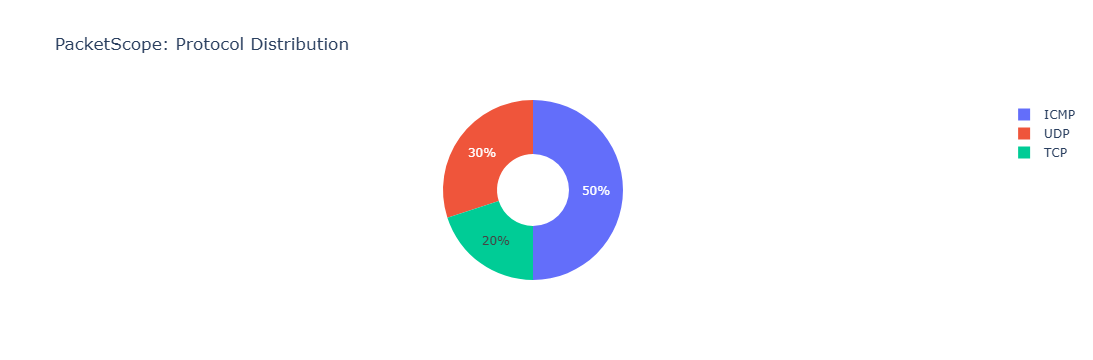

In [18]:
import plotly.express as px

protocol_counts = df["Protocol"].value_counts().reset_index()

protocol_counts.columns = ["Protocol", "Packets"]

fig = px.pie(
    protocol_counts,
    names="Protocol",
    values="Packets",
    title="PacketScope: Protocol Distribution",
    hole=0.4
)

fig.show()

In [19]:
import socket
import ipaddress

# Cache lookups so the same IP isn't queried repeatedly
hostname_cache = {}

def get_domain(ip):
    if ip in hostname_cache:
        return hostname_cache[ip]

    try:
        address = ipaddress.ip_address(ip)

        if address.is_private or address.is_link_local:
            result = "Local network"

        else:
            result = socket.gethostbyaddr(ip)[0]

    except (socket.herror, socket.gaierror, ValueError, OSError):
        result = "No hostname found"

    hostname_cache[ip] = result
    return result


df["Source Domain"] = df["Source IP"].apply(get_domain)
df["Destination Domain"] = df["Destination IP"].apply(get_domain)

display(df)

,IP Version,Protocol,Source IP,Destination IP,Source Port,Destination Port,Packet Size,TCP Flags,Source Domain,Destination Domain
0,IPv6,UDP,2600:140f:7200:3c::17d4:d6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,443.0,49810.0,90,NaN,g2600-140f-7200-003c-0000-0000-17d4-00d6.deplo...,DESKTOP-9HUUKV5.worldlink.com.np
1,IPv6,TCP,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2404:6800:4013:813::bc,55161.0,5228.0,75,A,DESKTOP-9HUUKV5.worldlink.com.np,lcdels-in-f188.1e100.net
2,IPv6,TCP,2404:6800:4013:813::bc,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,5228.0,55161.0,86,A,lcdels-in-f188.1e100.net,DESKTOP-9HUUKV5.worldlink.com.np
3,IPv6,UDP,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:7200:3c::17d4:d6,49810.0,443.0,91,NaN,DESKTOP-9HUUKV5.worldlink.com.np,g2600-140f-7200-003c-0000-0000-17d4-00d6.deplo...
4,IPv6,UDP,2600:140f:7200:3c::17d4:d6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,443.0,49810.0,90,NaN,g2600-140f-7200-003c-0000-0000-17d4-00d6.deplo...,DESKTOP-9HUUKV5.worldlink.com.np
5,IPv6,ICMP,fe80::1,fe80::9023:367b:d08f:15a1,NaN,NaN,86,NaN,Local network,Local network
6,IPv6,ICMP,fe80::9023:367b:d08f:15a1,fe80::1,NaN,NaN,86,NaN,Local network,Local network
7,IPv6,ICMP,2400:1a00:3b4c:5707::1,2400:1a00:3b4c:5707::2,NaN,NaN,86,NaN,No hostname found,DESKTOP-9HUUKV5.worldlink.com.np
8,IPv6,ICMP,2400:1a00:3b4c:5707::2,2400:1a00:3b4c:5707::1,NaN,NaN,86,NaN,DESKTOP-9HUUKV5.worldlink.com.np,No hostname found
9,IPv6,ICMP,2400:1a00:3b4c:5707::1,2400:1a00:3b4c:5707:3704:3e39:e4fb:761b,NaN,NaN,86,NaN,No hostname found,DESKTOP-9HUUKV5.worldlink.com.np


In [21]:
from scapy.all import sniff, conf, IP, IPv6, TCP, UDP
from scapy.layers.dns import DNS, DNSQR

import pandas as pd
import struct

In [22]:
print("Scapy:", conf.version)
print("Pandas:", pd.__version__)
print("Imports successful!")

Scapy: 2.8.0
Pandas: 3.1.0
Imports successful!


In [23]:
def extract_sni(data):
    try:
        # TLS handshake record
        if len(data) < 9 or data[0] != 22:
            return None

        # ClientHello handshake
        if data[5] != 1:
            return None

        pos = 9

        # Client version + random
        pos += 2 + 32

        # Session ID
        session_length = data[pos]
        pos += 1 + session_length

        # Cipher suites
        cipher_length = struct.unpack("!H", data[pos:pos+2])[0]
        pos += 2 + cipher_length

        # Compression methods
        compression_length = data[pos]
        pos += 1 + compression_length

        # Extensions
        extensions_length = struct.unpack("!H", data[pos:pos+2])[0]
        pos += 2
        end = pos + extensions_length

        while pos + 4 <= end:
            ext_type, ext_length = struct.unpack(
                "!HH", data[pos:pos+4]
            )
            pos += 4

            if ext_type == 0:  # Server Name extension
                extension_data = data[pos:pos+ext_length]

                name_length = struct.unpack(
                    "!H", extension_data[3:5]
                )[0]

                name = extension_data[5:5+name_length]

                return name.decode("utf-8", errors="ignore")

            pos += ext_length

    except (IndexError, struct.error):
        return None

    return None

In [24]:
captured = sniff(
    iface=wifi,
    filter="port 53 or tcp port 443",
    timeout=90,
    store=True
)

print("Captured:", len(captured))

Captured: 31766


In [25]:
tls_records = []

for packet in captured:

    if TCP not in packet or packet[TCP].dport != 443:
        continue

    domain = extract_sni(bytes(packet[TCP].payload))

    if domain:

        if IP in packet:
            src = packet[IP].src
            dst = packet[IP].dst
        elif IPv6 in packet:
            src = packet[IPv6].src
            dst = packet[IPv6].dst
        else:
            continue

        tls_records.append({
            "Detection": "TLS SNI",
            "Domain": domain,
            "Source IP": src,
            "Destination IP": dst
        })

tls_df = pd.DataFrame(tls_records)

display(tls_df)

,Detection,Domain,Source IP,Destination IP
0,TLS SNI,assets.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2400:1a00:cd11:a112::67d3:9568
1,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1
2,TLS SNI,browser.events.data.msn.com,192.168.1.83,20.89.1.13
3,TLS SNI,srtb.msn.com,192.168.1.83,150.171.27.10
4,TLS SNI,www.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:7200:3c::17d4:c5
...,...,...,...,...
69,TLS SNI,platform.twitter.com,192.168.1.83,151.101.104.157
70,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629
71,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629
72,TLS SNI,realtime-signalr.roblox.com,192.168.1.83,128.116.50.3


In [26]:
domain_summary = (
    tls_df.groupby("Domain")
    .agg(
        Observations=("Domain", "count"),
        Destination_IPs=("Destination IP",
                         lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("Observations", ascending=False)
)

display(domain_summary)

,Domain,Observations,Destination_IPs
23,r.msftstatic.com,7,2620:1ec:33:1::10
22,r.bing.com,6,"2600:140f:e::b81a:3609, 2600:140f:e::b81a:3629"
33,www.bing.com,4,2600:140f:7200:3c::17d4:c5
36,www.gstatic.com,4,2404:6800:4002:81d::2003
41,yt3.ggpht.com,3,2404:6800:4003:c03::84
12,github.githubassets.com,3,2606:50c0:8000::215
9,edge.microsoft.com,3,2620:1ec:33::11
24,realtime-signalr.roblox.com,3,"128.116.50.3, 128.116.97.3"
1,analytics.google.com,2,"2001:4860:4802:32::181, 2001:4860:4802:34::181"
0,accounts.google.com,2,2404:6800:4013:813::54


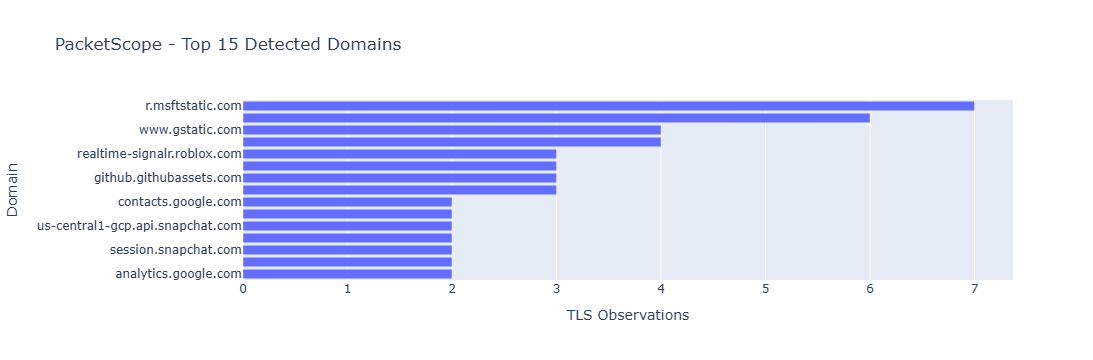

In [27]:
import plotly.express as px

top_domains = domain_summary.head(15)

fig = px.bar(
    top_domains,
    x="Observations",
    y="Domain",
    orientation="h",
    title="PacketScope - Top 15 Detected Domains",
    labels={"Observations": "TLS Observations"}
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

In [33]:
from pathlib import Path

PROJECT = Path.cwd() / "Project_5"

(PROJECT / "data").mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT)

Project folder: C:\Project_5\Project_5


In [34]:
tls_df.to_csv(PROJECT / "data" / "tls_domains.csv", index=False)

domain_summary.to_csv(
    PROJECT / "data" / "domain_summary.csv",
    index=False
)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


In [35]:
from scapy.layers.dns import DNS
from scapy.all import IP, IPv6

dns_mappings = []

for packet in captured:

    if DNS not in packet:
        continue

    dns = packet[DNS]

    # Only DNS responses
    if dns.qr != 1:
        continue

    # Get the requested domain
    domain = "Unknown"

    if dns.qd:
        domain = dns.qd.qname.decode(
            "utf-8", errors="ignore"
        ).rstrip(".")

    # Extract returned IP addresses
    for i in range(dns.ancount):

        answer = dns.an[i]

        if answer.type == 1:  # IPv4 A record
            address = answer.rdata
            record_type = "A"

        elif answer.type == 28:  # IPv6 AAAA record
            address = answer.rdata
            record_type = "AAAA"

        else:
            continue

        dns_mappings.append({
            "Domain": domain,
            "Resolved IP": str(address),
            "Record Type": record_type
        })

dns_map_df = pd.DataFrame(dns_mappings)

display(dns_map_df)

,Domain,Resolved IP,Record Type
0,www.google.com,2001:4860:482a:7700::,AAAA
1,www.google.com,2001:4860:4829:7700::,AAAA
2,www.google.com,2001:4860:4827:7700::,AAAA
3,www.google.com,2001:4860:482d:7700::,AAAA
4,www.google.com,2001:4860:482b:7700::,AAAA
...,...,...,...
1024,google.com,142.250.118.101,A
1025,google.com,142.250.118.102,A
1026,google.com,142.250.118.100,A
1027,google.com,142.250.118.139,A


In [36]:
dns_map_clean = dns_map_df.drop_duplicates(
    subset=["Domain", "Resolved IP", "Record Type"]
).reset_index(drop=True)

print("Original DNS records:", len(dns_map_df))
print("Unique DNS mappings:", len(dns_map_clean))

display(dns_map_clean)

Original DNS records: 1029
Unique DNS mappings: 469


,Domain,Resolved IP,Record Type
0,www.google.com,2001:4860:482a:7700::,AAAA
1,www.google.com,2001:4860:4829:7700::,AAAA
2,www.google.com,2001:4860:4827:7700::,AAAA
3,www.google.com,2001:4860:482d:7700::,AAAA
4,www.google.com,2001:4860:482b:7700::,AAAA
...,...,...,...
464,google.com,142.250.118.101,A
465,google.com,142.250.118.102,A
466,google.com,142.250.118.100,A
467,google.com,142.250.118.139,A


In [37]:
network_activity = pd.merge(
    tls_df,
    dns_map_clean,
    left_on="Destination IP",
    right_on="Resolved IP",
    how="left"
)

network_activity = network_activity.drop(
    columns=["Resolved IP"]
)

display(network_activity)

,Detection,Domain_x,Source IP,Destination IP,Domain_y,Record Type
0,TLS SNI,assets.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2400:1a00:cd11:a112::67d3:9568,assets.msn.com,AAAA
1,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,c.msn.com,AAAA
2,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,xpaywalletcdn-prod.azureedge.net,AAAA
3,TLS SNI,browser.events.data.msn.com,192.168.1.83,20.89.1.13,browser.events.data.msn.com,A
4,TLS SNI,srtb.msn.com,192.168.1.83,150.171.27.10,c.bing.com,A
...,...,...,...,...,...,...
96,TLS SNI,platform.twitter.com,192.168.1.83,151.101.104.157,platform.twitter.com,A
97,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,r.bing.com,AAAA
98,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,r.bing.com,AAAA
99,TLS SNI,realtime-signalr.roblox.com,192.168.1.83,128.116.50.3,realtime-signalr.roblox.com,A


In [38]:
network_activity = network_activity[
    [
        "Detection",
        "Domain",
        "Source IP",
        "Destination IP",
        "Record Type"
    ]
].drop_duplicates().reset_index(drop=True)

display(network_activity)

KeyError: "['Domain'] not in index"

In [39]:
print(network_activity.columns.tolist())

['Detection', 'Domain_x', 'Source IP', 'Destination IP', 'Domain_y', 'Record Type']


In [40]:
network_activity = network_activity[
    [
        "Detection",
        "Domain_x",
        "Source IP",
        "Destination IP",
        "Record Type"
    ]
].copy()

network_activity = network_activity.rename(
    columns={"Domain_x": "Domain"}
)

display(network_activity)

,Detection,Domain,Source IP,Destination IP,Record Type
0,TLS SNI,assets.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2400:1a00:cd11:a112::67d3:9568,AAAA
1,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,AAAA
2,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,AAAA
3,TLS SNI,browser.events.data.msn.com,192.168.1.83,20.89.1.13,A
4,TLS SNI,srtb.msn.com,192.168.1.83,150.171.27.10,A
...,...,...,...,...,...
96,TLS SNI,platform.twitter.com,192.168.1.83,151.101.104.157,A
97,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,AAAA
98,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,AAAA
99,TLS SNI,realtime-signalr.roblox.com,192.168.1.83,128.116.50.3,A


In [41]:
local_ips = {
    "192.168.1.83",
    "2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d"
}

def identify_direction(row):

    if row["Source IP"] in local_ips:
        return "Outgoing"

    elif row["Destination IP"] in local_ips:
        return "Incoming"

    return "External / Unknown"


network_activity["Direction"] = (
    network_activity.apply(identify_direction, axis=1)
)

display(network_activity)

,Detection,Domain,Source IP,Destination IP,Record Type,Direction
0,TLS SNI,assets.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2400:1a00:cd11:a112::67d3:9568,AAAA,Outgoing
1,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,AAAA,Outgoing
2,TLS SNI,c.msn.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2603:1061:14:150::1,AAAA,Outgoing
3,TLS SNI,browser.events.data.msn.com,192.168.1.83,20.89.1.13,A,Outgoing
4,TLS SNI,srtb.msn.com,192.168.1.83,150.171.27.10,A,Outgoing
...,...,...,...,...,...,...
96,TLS SNI,platform.twitter.com,192.168.1.83,151.101.104.157,A,Outgoing
97,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,AAAA,Outgoing
98,TLS SNI,r.bing.com,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,2600:140f:e::b81a:3629,AAAA,Outgoing
99,TLS SNI,realtime-signalr.roblox.com,192.168.1.83,128.116.50.3,A,Outgoing


In [42]:
direction_counts = (
    network_activity["Direction"]
    .value_counts()
    .reset_index()
)

direction_counts.columns = ["Direction", "Count"]

display(direction_counts)

,Direction,Count
0,Outgoing,101


In [43]:
from collections import Counter

direction_counts = Counter()

for packet in captured:

    if IP in packet:
        src = packet[IP].src
        dst = packet[IP].dst

    elif IPv6 in packet:
        src = packet[IPv6].src
        dst = packet[IPv6].dst

    else:
        continue

    if src in local_ips:
        direction_counts["Outgoing"] += 1

    elif dst in local_ips:
        direction_counts["Incoming"] += 1

    else:
        direction_counts["Other"] += 1

print(dict(direction_counts))

{'Incoming': 19315, 'Outgoing': 12451}


In [44]:
from scapy.all import TCP
from collections import Counter

tcp_flags = Counter()

for packet in captured:
    if TCP in packet:
        tcp_flags[str(packet[TCP].flags)] += 1

print("TCP Flag Distribution:")

for flag, count in tcp_flags.items():
    print(flag, ":", count)

TCP Flag Distribution:
PA : 9746
A : 20312
FA : 109
RA : 39
R : 110
S : 168
SA : 167


In [45]:
from scapy.all import TCP, IP, IPv6

handshake_packets = []

for packet in captured:
    if TCP not in packet:
        continue

    flags = packet[TCP].flags

    if flags == 2 or flags == 18:  # SYN or SYN-ACK
        if IP in packet:
            src = packet[IP].src
            dst = packet[IP].dst
        elif IPv6 in packet:
            src = packet[IPv6].src
            dst = packet[IPv6].dst
        else:
            continue

        handshake_packets.append({
            "Flags": str(flags),
            "Source IP": src,
            "Source Port": packet[TCP].sport,
            "Destination IP": dst,
            "Destination Port": packet[TCP].dport,
            "Time": float(packet.time)
        })

handshake_df = pd.DataFrame(handshake_packets)

display(handshake_df.head(20))

,Flags,Source IP,Source Port,Destination IP,Destination Port,Time
0,S,192.168.1.83,57012,20.89.1.13,443,1.793704e+09
1,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,1.793704e+09
2,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,1.793704e+09
3,SA,2400:1a00:cd11:a112::67d3:9568,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,1.793704e+09
4,S,192.168.1.83,57015,13.225.5.126,443,1.793704e+09
5,S,192.168.1.83,57016,20.89.1.13,443,1.793704e+09
6,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57017,2603:1061:14:150::1,443,1.793704e+09
7,S,192.168.1.83,57018,20.89.1.13,443,1.793704e+09
8,S,192.168.1.83,57019,20.89.1.13,443,1.793704e+09
9,S,192.168.1.83,57020,150.171.110.81,443,1.793704e+09


In [46]:
# Create an IP-to-domain lookup from TLS SNI records
ip_domain_map = (
    tls_df.groupby("Destination IP")["Domain"]
    .apply(lambda x: ", ".join(sorted(set(x))))
    .to_dict()
)

# Add domain names to the handshake table
handshake_df["Domain"] = handshake_df["Destination IP"].map(ip_domain_map)

handshake_df["Domain"] = handshake_df["Domain"].fillna(
    "Domain not detected"
)

display(handshake_df.head(20))

,Flags,Source IP,Source Port,Destination IP,Destination Port,Time,Domain
0,S,192.168.1.83,57012,20.89.1.13,443,1.793704e+09,browser.events.data.msn.com
1,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,1.793704e+09,"c.msn.com, xpaywalletcdn-prod.azureedge.net"
2,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,1.793704e+09,assets.msn.com
3,SA,2400:1a00:cd11:a112::67d3:9568,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,1.793704e+09,Domain not detected
4,S,192.168.1.83,57015,13.225.5.126,443,1.793704e+09,Domain not detected
5,S,192.168.1.83,57016,20.89.1.13,443,1.793704e+09,browser.events.data.msn.com
6,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57017,2603:1061:14:150::1,443,1.793704e+09,"c.msn.com, xpaywalletcdn-prod.azureedge.net"
7,S,192.168.1.83,57018,20.89.1.13,443,1.793704e+09,browser.events.data.msn.com
8,S,192.168.1.83,57019,20.89.1.13,443,1.793704e+09,browser.events.data.msn.com
9,S,192.168.1.83,57020,150.171.110.81,443,1.793704e+09,Domain not detected


In [47]:
from scapy.all import TCP, IP, IPv6

handshake_events = []

for packet in captured:
    if TCP not in packet:
        continue

    flags = int(packet[TCP].flags)

    # Only pure SYN, SYN-ACK and ACK packets
    if flags not in [2, 18, 16]:
        continue

    if IP in packet:
        src = packet[IP].src
        dst = packet[IP].dst
    elif IPv6 in packet:
        src = packet[IPv6].src
        dst = packet[IPv6].dst
    else:
        continue

    handshake_events.append({
        "Flags": str(packet[TCP].flags),
        "Source IP": src,
        "Source Port": packet[TCP].sport,
        "Destination IP": dst,
        "Destination Port": packet[TCP].dport,
        "Time": float(packet.time)
    })

handshake_events_df = pd.DataFrame(handshake_events)

display(handshake_events_df.head(30))

,Flags,Source IP,Source Port,Destination IP,Destination Port,Time
0,A,2606:4700:4403::ac40:94eb,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,56741,1.793704e+09
1,A,192.168.1.83,55990,128.116.97.3,443,1.793704e+09
2,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09
3,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09
4,A,192.168.1.83,55990,128.116.97.3,443,1.793704e+09
5,A,192.168.1.83,55987,128.116.97.3,443,1.793704e+09
6,A,192.168.1.83,55987,128.116.97.3,443,1.793704e+09
7,A,128.116.97.3,443,192.168.1.83,55987,1.793704e+09
8,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09
9,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09


In [48]:
print(handshake_events_df["Flags"].value_counts())

Flags
A     20312
S       168
SA      167
Name: count, dtype: int64


In [49]:
for flag in ["S", "SA", "A"]:
    print(f"\n--- {flag} packets ---")
    display(
        handshake_events_df[
            handshake_events_df["Flags"] == flag
        ].head(5)
    )


--- S packets ---


,Flags,Source IP,Source Port,Destination IP,Destination Port,Time
68,S,192.168.1.83,57012,20.89.1.13,443,1.793704e+09
69,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,1.793704e+09
70,S,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,1.793704e+09
75,S,192.168.1.83,57015,13.225.5.126,443,1.793704e+09
76,S,192.168.1.83,57016,20.89.1.13,443,1.793704e+09



--- SA packets ---


,Flags,Source IP,Source Port,Destination IP,Destination Port,Time
71,SA,2400:1a00:cd11:a112::67d3:9568,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,1.793704e+09
82,SA,2603:1061:14:150::1,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,1.793704e+09
84,SA,13.225.5.126,443,192.168.1.83,57015,1.793704e+09
85,SA,20.89.1.13,443,192.168.1.83,57012,1.793704e+09
86,SA,2603:1061:14:150::1,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57017,1.793704e+09



--- A packets ---


,Flags,Source IP,Source Port,Destination IP,Destination Port,Time
0,A,2606:4700:4403::ac40:94eb,443,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,56741,1.793704e+09
1,A,192.168.1.83,55990,128.116.97.3,443,1.793704e+09
2,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09
3,A,128.116.97.3,443,192.168.1.83,55990,1.793704e+09
4,A,192.168.1.83,55990,128.116.97.3,443,1.793704e+09


In [50]:
from scapy.all import TCP, IP, IPv6

tcp_packets = []

for p in captured:
    if TCP not in p:
        continue

    if IP in p:
        src, dst = p[IP].src, p[IP].dst
    elif IPv6 in p:
        src, dst = p[IPv6].src, p[IPv6].dst
    else:
        continue

    tcp_packets.append({
        "src": src,
        "dst": dst,
        "sport": p[TCP].sport,
        "dport": p[TCP].dport,
        "flags": int(p[TCP].flags),
        "seq": p[TCP].seq,
        "ack": p[TCP].ack,
        "time": float(p.time)
    })

completed = []

for syn in tcp_packets:
    if syn["flags"] != 2:
        continue

    # Find the matching server SYN-ACK
    synack = next((
        p for p in tcp_packets
        if p["src"] == syn["dst"]
        and p["dst"] == syn["src"]
        and p["sport"] == syn["dport"]
        and p["dport"] == syn["sport"]
        and p["flags"] == 18
        and p["ack"] == (syn["seq"] + 1) % (2**32)
        and p["time"] >= syn["time"]
    ), None)

    if synack is None:
        continue

    # Find the client's final ACK
    final_ack = next((
        p for p in tcp_packets
        if p["src"] == syn["src"]
        and p["dst"] == syn["dst"]
        and p["sport"] == syn["sport"]
        and p["dport"] == syn["dport"]
        and (p["flags"] & 0x10)
        and not (p["flags"] & 0x06)
        and p["seq"] == (syn["seq"] + 1) % (2**32)
        and p["ack"] == (synack["seq"] + 1) % (2**32)
        and p["time"] >= synack["time"]
    ), None)

    if final_ack:
        completed.append({
            "Client IP": syn["src"],
            "Client Port": syn["sport"],
            "Server IP": syn["dst"],
            "Server Port": syn["dport"],
            "Handshake": "Completed",
            "Time": final_ack["time"] - syn["time"]
        })

completed_df = pd.DataFrame(completed)

display(completed_df)
print("Completed handshakes:", len(completed_df))

,Client IP,Client Port,Server IP,Server Port,Handshake,Time
0,192.168.1.83,57012,20.89.1.13,443,Completed,0.334987
1,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,Completed,0.319535
2,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,Completed,0.009063
3,192.168.1.83,57015,13.225.5.126,443,Completed,0.253215
4,192.168.1.83,57016,20.89.1.13,443,Completed,0.152801
...,...,...,...,...,...,...
156,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57183,2600:140f:e::b81a:3629,443,Completed,0.068754
157,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57184,2620:1ec:33:1::10,443,Completed,0.044465
158,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57185,2620:1ec:33:1::10,443,Completed,0.043211
159,192.168.1.83,57186,128.116.50.3,443,Completed,0.092226


Completed handshakes: 161


In [51]:
print("Total detected handshakes:", len(completed_df))

print("\nHandshake Time Statistics:")
print(completed_df["Time"].describe())

print("\nAverage:", round(completed_df["Time"].mean() * 1000, 2), "ms")
print("Fastest:", round(completed_df["Time"].min() * 1000, 2), "ms")
print("Slowest:", round(completed_df["Time"].max() * 1000, 2), "ms")

Total detected handshakes: 161

Handshake Time Statistics:
count    161.000000
mean       0.074818
std        0.067782
min        0.005318
25%        0.027488
50%        0.049668
75%        0.092226
max        0.334987
Name: Time, dtype: float64

Average: 74.82 ms
Fastest: 5.32 ms
Slowest: 334.99 ms


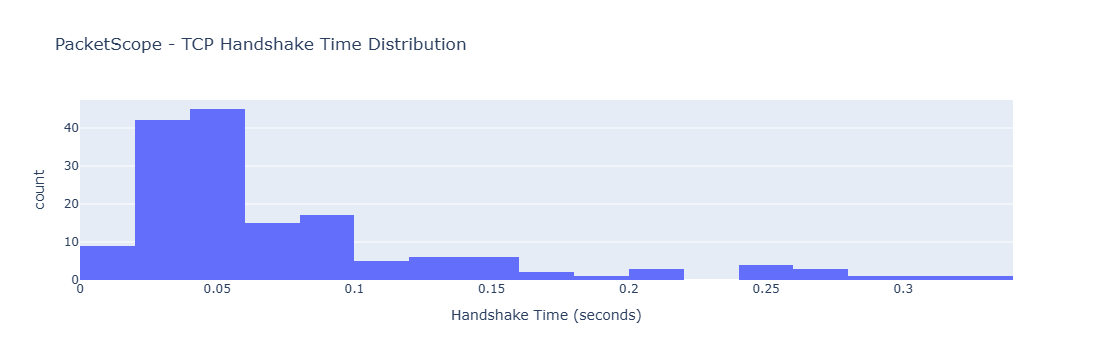

In [52]:
import plotly.express as px

fig = px.histogram(
    completed_df,
    x="Time",
    nbins=25,
    title="PacketScope - TCP Handshake Time Distribution",
    labels={"Time": "Handshake Time (seconds)"}
)

fig.show()

In [53]:
from scapy.all import TCP, IP, IPv6

# Extract TLS ClientHello observations with their TCP connection details
tls_connections = []

for p in captured:
    if TCP not in p or p[TCP].dport != 443:
        continue

    domain = extract_sni(bytes(p[TCP].payload))

    if not domain:
        continue

    if IP in p:
        src, dst = p[IP].src, p[IP].dst
    elif IPv6 in p:
        src, dst = p[IPv6].src, p[IPv6].dst
    else:
        continue

    tls_connections.append({
        "Client IP": src,
        "Client Port": p[TCP].sport,
        "Server IP": dst,
        "Server Port": p[TCP].dport,
        "Domain": domain
    })

tls_connection_df = pd.DataFrame(tls_connections).drop_duplicates()

display(tls_connection_df.head(15))

,Client IP,Client Port,Server IP,Server Port,Domain
0,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,assets.msn.com
1,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,c.msn.com
2,192.168.1.83,57012,20.89.1.13,443,browser.events.data.msn.com
3,192.168.1.83,57025,150.171.27.10,443,srtb.msn.com
4,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57027,2600:140f:7200:3c::17d4:c5,443,www.bing.com
5,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57028,2600:140f:7200:3c::17d4:c5,443,www.bing.com
6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57026,2600:140f:7200:3c::17d4:c5,443,www.bing.com
7,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57031,2600:140f:7200:3c::17d4:c5,443,www.bing.com
8,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57033,2600:140f:e::b81a:3609,443,r.bing.com
9,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57035,2620:1ec:33:1::10,443,r.msftstatic.com


In [54]:
report_df = completed_df.merge(
    tls_connection_df,
    on=[
        "Client IP",
        "Client Port",
        "Server IP",
        "Server Port"
    ],
    how="left"
)

report_df["Domain"] = report_df["Domain"].fillna(
    "Domain not detected"
)

display(
    report_df[
        [
            "Client IP",
            "Client Port",
            "Server IP",
            "Server Port",
            "Domain",
            "Handshake",
            "Time"
        ]
    ].head(25)
)

,Client IP,Client Port,Server IP,Server Port,Domain,Handshake,Time
0,192.168.1.83,57012,20.89.1.13,443,browser.events.data.msn.com,Completed,0.334987
1,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57013,2603:1061:14:150::1,443,c.msn.com,Completed,0.319535
2,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57014,2400:1a00:cd11:a112::67d3:9568,443,assets.msn.com,Completed,0.009063
3,192.168.1.83,57015,13.225.5.126,443,Domain not detected,Completed,0.253215
4,192.168.1.83,57016,20.89.1.13,443,Domain not detected,Completed,0.152801
5,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57017,2603:1061:14:150::1,443,Domain not detected,Completed,0.065586
6,192.168.1.83,57018,20.89.1.13,443,Domain not detected,Completed,0.154365
7,192.168.1.83,57019,20.89.1.13,443,Domain not detected,Completed,0.163646
8,192.168.1.83,57021,13.225.5.126,443,Domain not detected,Completed,0.046278
9,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,57022,2400:1a00:cd11:a112::67d3:9568,443,Domain not detected,Completed,0.009589


In [55]:
domain_connections = (
    report_df[report_df["Domain"] != "Domain not detected"]
    .groupby("Domain")
    .agg(
        Connections=("Client Port", "nunique"),
        Avg_Handshake_ms=("Time", lambda x: round(x.mean() * 1000, 2)),
        Server_IPs=("Server IP", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("Connections", ascending=False)
)

display(domain_connections)

,Domain,Connections,Avg_Handshake_ms,Server_IPs
23,r.msftstatic.com,7,61.49,2620:1ec:33:1::10
22,r.bing.com,6,74.42,"2600:140f:e::b81a:3609, 2600:140f:e::b81a:3629"
33,www.bing.com,4,49.69,2600:140f:7200:3c::17d4:c5
36,www.gstatic.com,4,21.86,2404:6800:4002:81d::2003
41,yt3.ggpht.com,3,123.86,2404:6800:4003:c03::84
12,github.githubassets.com,3,48.91,2606:50c0:8000::215
9,edge.microsoft.com,3,121.92,2620:1ec:33::11
24,realtime-signalr.roblox.com,3,126.00,"128.116.50.3, 128.116.97.3"
1,analytics.google.com,2,164.19,"2001:4860:4802:32::181, 2001:4860:4802:34::181"
0,accounts.google.com,2,27.86,2404:6800:4013:813::54


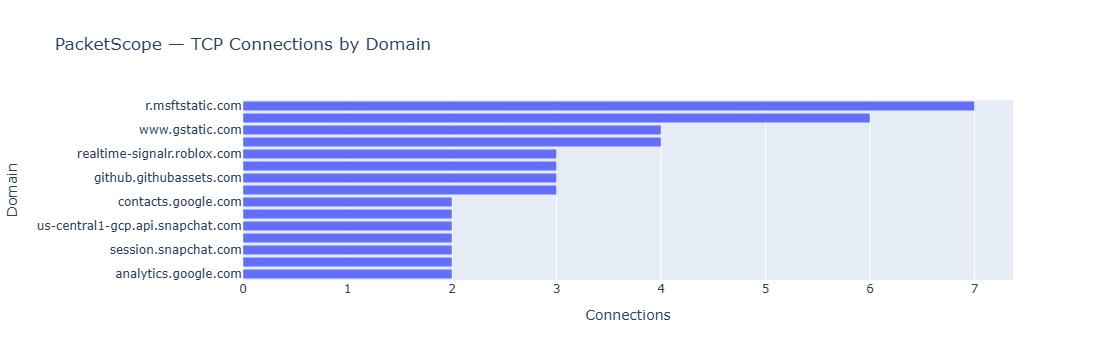

In [56]:
fig = px.bar(
    domain_connections.head(15),
    x="Connections",
    y="Domain",
    orientation="h",
    title="PacketScope — TCP Connections by Domain"
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

In [57]:
display(domain_connections.head(15))


,Domain,Connections,Avg_Handshake_ms,Server_IPs
23,r.msftstatic.com,7,61.49,2620:1ec:33:1::10
22,r.bing.com,6,74.42,"2600:140f:e::b81a:3609, 2600:140f:e::b81a:3629"
33,www.bing.com,4,49.69,2600:140f:7200:3c::17d4:c5
36,www.gstatic.com,4,21.86,2404:6800:4002:81d::2003
41,yt3.ggpht.com,3,123.86,2404:6800:4003:c03::84
12,github.githubassets.com,3,48.91,2606:50c0:8000::215
9,edge.microsoft.com,3,121.92,2620:1ec:33::11
24,realtime-signalr.roblox.com,3,126.00,"128.116.50.3, 128.116.97.3"
1,analytics.google.com,2,164.19,"2001:4860:4802:32::181, 2001:4860:4802:34::181"
0,accounts.google.com,2,27.86,2404:6800:4013:813::54


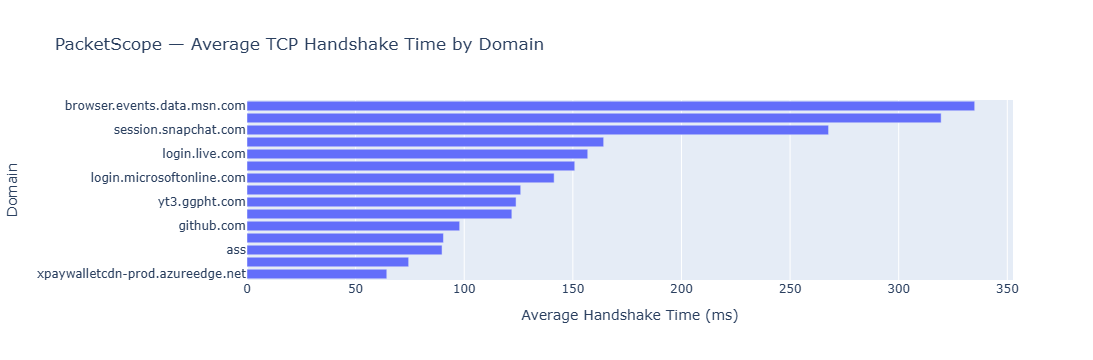

In [58]:
fig = px.bar(
    domain_connections.sort_values(
        "Avg_Handshake_ms", ascending=False
    ).head(15),
    x="Avg_Handshake_ms",
    y="Domain",
    orientation="h",
    title="PacketScope — Average TCP Handshake Time by Domain",
    labels={
        "Avg_Handshake_ms": "Average Handshake Time (ms)",
        "Domain": "Domain"
    }
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

In [59]:
udp_records = []

for packet in captured:

    if UDP not in packet:
        continue

    if IP in packet:
        src = packet[IP].src
        dst = packet[IP].dst
        version = "IPv4"

    elif IPv6 in packet:
        src = packet[IPv6].src
        dst = packet[IPv6].dst
        version = "IPv6"

    else:
        continue

    udp_records.append({
        "IP Version": version,
        "Source IP": src,
        "Source Port": packet[UDP].sport,
        "Destination IP": dst,
        "Destination Port": packet[UDP].dport,
        "Packet Size": len(packet)
    })

udp_df = pd.DataFrame(udp_records)

display(udp_df.head(15))
print("Total UDP packets:", len(udp_df))

,IP Version,Source IP,Source Port,Destination IP,Destination Port,Packet Size
0,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,51531,2400:1a00:0:32::165,53,94
1,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58852,2400:1a00:0:32::165,53,94
2,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,50085,2400:1a00:8000:4::73,53,92
3,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,62944,2400:1a00:0:32::165,53,94
4,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,59927,2400:1a00:8000:4::73,53,92
5,IPv6,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58777,2400:1a00:8000:4::73,53,92
6,IPv6,2400:1a00:0:32::165,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58852,318
7,IPv6,2400:1a00:0:32::165,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,51531,119
8,IPv6,2400:1a00:8000:4::73,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,59927,269
9,IPv6,2400:1a00:8000:4::73,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58777,261


Total UDP packets: 1115


In [60]:
from scapy.layers.dns import DNS

udp_domain_records = []

for packet in captured:

    if UDP not in packet:
        continue

    if IP in packet:
        src, dst = packet[IP].src, packet[IP].dst
    elif IPv6 in packet:
        src, dst = packet[IPv6].src, packet[IPv6].dst
    else:
        continue

    domain = "No DNS domain detected"
    dns_type = "Not DNS"

    if DNS in packet:
        dns = packet[DNS]

        if dns.qd:
            domain = dns.qd.qname.decode(
                "utf-8", errors="ignore"
            ).rstrip(".")

            dns_type = "DNS Response" if dns.qr == 1 else "DNS Query"

    udp_domain_records.append({
        "Domain": domain,
        "DNS Type": dns_type,
        "Source IP": src,
        "Source Port": packet[UDP].sport,
        "Destination IP": dst,
        "Destination Port": packet[UDP].dport,
        "Packet Size": len(packet)
    })

udp_domain_df = pd.DataFrame(udp_domain_records)

display(udp_domain_df.head(20))

,Domain,DNS Type,Source IP,Source Port,Destination IP,Destination Port,Packet Size
0,www.google.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,51531,2400:1a00:0:32::165,53,94
1,www.google.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58852,2400:1a00:0:32::165,53,94
2,www.bing.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,50085,2400:1a00:8000:4::73,53,92
3,www.google.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,62944,2400:1a00:0:32::165,53,94
4,www.bing.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,59927,2400:1a00:8000:4::73,53,92
5,www.bing.com,DNS Query,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58777,2400:1a00:8000:4::73,53,92
6,www.google.com,DNS Response,2400:1a00:0:32::165,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58852,318
7,www.google.com,DNS Response,2400:1a00:0:32::165,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,51531,119
8,www.bing.com,DNS Response,2400:1a00:8000:4::73,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,59927,269
9,www.bing.com,DNS Response,2400:1a00:8000:4::73,53,2400:1a00:3b4c:5707:c1eb:a7b4:9d73:1a4d,58777,261


In [61]:
dns_queries = udp_domain_df[
    udp_domain_df["DNS Type"] == "DNS Query"
].copy()

udp_domain_summary = (
    dns_queries.groupby("Domain")
    .agg(
        DNS_Requests=("Domain", "count"),
        DNS_Servers=("Destination IP",
                     lambda x: ", ".join(sorted(set(x)))),
        Avg_Packet_Size=("Packet Size", "mean")
    )
    .reset_index()
    .sort_values("DNS_Requests", ascending=False)
)

udp_domain_summary["Avg_Packet_Size"] = (
    udp_domain_summary["Avg_Packet_Size"].round(2)
)

display(udp_domain_summary.head(20))

,Domain,DNS_Requests,DNS_Servers,Avg_Packet_Size
82,www.bing.com,50,2400:1a00:8000:4::73,92.0
64,setpati.com,30,"2400:1a00:0:32::165, 2400:1a00:8000:4::73",91.0
41,login.live.com,19,2400:1a00:8000:4::73,94.0
25,edge.microsoft.com,18,2400:1a00:8000:4::73,98.0
44,mail.google.com,17,2400:1a00:8000:4::73,95.0
47,ntp.msn.com,15,2400:1a00:8000:4::73,91.0
0,accounts.google.com,13,2400:1a00:8000:4::73,99.0
85,www.google.com,12,"2400:1a00:0:32::165, 2400:1a00:8000:4::73",94.0
42,login.microsoftonline.com,11,2400:1a00:8000:4::73,105.0
83,www.facebook.com,10,2400:1a00:8000:4::73,96.0


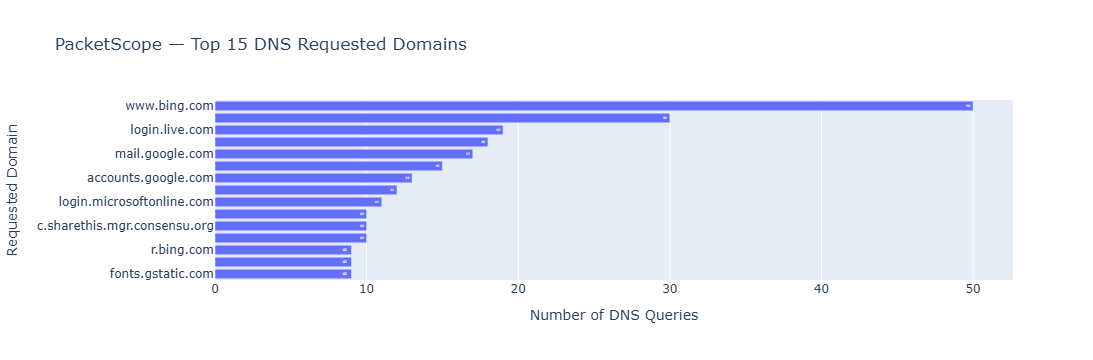

In [62]:
fig = px.bar(
    udp_domain_summary.head(15),
    x="DNS_Requests",
    y="Domain",
    orientation="h",
    title="PacketScope — Top 15 DNS Requested Domains",
    labels={
        "DNS_Requests": "Number of DNS Queries",
        "Domain": "Requested Domain"
    },
    text="DNS_Requests"
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

In [63]:
udp_port_summary = (
    udp_df.groupby("Destination Port")
    .agg(
        Packets=("Destination Port", "count"),
        Domains=("Destination Port", lambda x: "-")
    )
    .reset_index()
    .sort_values("Packets", ascending=False)
)

display(udp_port_summary.head(15))

,Destination Port,Packets,Domains
0,53,559,-
96,51736,3,-
71,51082,2,-
105,52090,2,-
102,51968,2,-
34,50085,2,-
118,52505,2,-
26,49788,2,-
68,50897,2,-
107,52278,2,-


In [64]:
udp_port_domains = (
    udp_domain_df.groupby("Destination Port")
    .agg(
        Packets=("Destination Port", "count"),
        Domains=("Domain", lambda x: ", ".join(sorted(set(
            d for d in x if d != "No DNS domain detected"
        ))))
    )
    .reset_index()
    .sort_values("Packets", ascending=False)
)

display(udp_port_domains.head(15))

,Destination Port,Packets,Domains
0,53,559,"accounts.google.com, accounts.youtube.com, add..."
96,51736,3,"nav-edge.smartscreen.microsoft.com, wpad.world..."
71,51082,2,"nav-edge.smartscreen.microsoft.com, www.bing.com"
105,52090,2,setpati.com
102,51968,2,"deff.nelreports.net, login.microsoftonline.com"
34,50085,2,"r.msftstatic.com, www.bing.com"
118,52505,2,"pro.fontawesome.com, signaler-pa.clients6.goog..."
26,49788,2,realtime-signalr.roblox.com
68,50897,2,"scontent.xx.fbcdn.net, www.google.com"
107,52278,2,"www.google.com.np, xpaywalletcdn-prod.azureedg..."


In [65]:
dns_port_analysis = (
    udp_domain_df[
        udp_domain_df["DNS Type"] == "DNS Query"
    ]
    .groupby("Destination Port")
    .agg(
        Packets=("Destination Port", "count"),
        Domains=("Domain", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("Packets", ascending=False)
)

display(dns_port_analysis)

,Destination Port,Packets,Domains
0,53,559,"accounts.google.com, accounts.youtube.com, add..."


In [66]:
quic_packets = sniff(
    iface=wifi,
    filter="udp port 443",
    timeout=60,
    store=True
)

print("UDP 443 packets captured:", len(quic_packets))

UDP 443 packets captured: 19108


In [67]:
# Build IP-to-domain mapping from DNS records
ip_domain_map = (
    dns_map_clean.groupby("Resolved IP")["Domain"]
    .apply(lambda x: ", ".join(sorted(set(x))))
    .to_dict()
)

quic_records = []

for packet in quic_packets:

    if IP in packet:
        src, dst = packet[IP].src, packet[IP].dst
    elif IPv6 in packet:
        src, dst = packet[IPv6].src, packet[IPv6].dst
    else:
        continue

    if src in local_ips:
        direction = "Outgoing"
        remote_ip = dst
    elif dst in local_ips:
        direction = "Incoming"
        remote_ip = src
    else:
        direction = "Other"
        remote_ip = dst

    quic_records.append({
        "Domain": ip_domain_map.get(
            remote_ip, "Domain not detected"
        ),
        "Remote IP": remote_ip,
        "Direction": direction,
        "Source Port": packet[UDP].sport,
        "Destination Port": packet[UDP].dport,
        "Packet Size": len(packet)
    })

quic_df = pd.DataFrame(quic_records)

display(quic_df.head(20))

print("Total UDP 443 packets:", len(quic_df))

,Domain,Remote IP,Direction,Source Port,Destination Port,Packet Size
0,www.bing.com,2600:140f:7200:3c::17d4:c5,Outgoing,50441,443,91
1,www.bing.com,2600:140f:7200:3c::17d4:c5,Incoming,443,50441,90
2,www.google.com,2001:4860:482a:7700::,Outgoing,49561,443,91
3,www.bing.com,2600:140f:7200:3c::17d4:c5,Outgoing,50441,443,91
4,www.google.com,2001:4860:482a:7700::,Incoming,443,49561,90
5,www.bing.com,2600:140f:7200:3c::17d4:c5,Incoming,443,50441,90
6,Domain not detected,2a06:98c1:310b::ac40:92d7,Incoming,443,63688,678
7,Domain not detected,2a06:98c1:310b::ac40:92d7,Outgoing,63688,443,107
8,www.bing.com,2600:140f:7200:3c::17d4:c5,Outgoing,50441,443,91
9,www.bing.com,2600:140f:7200:3c::17d4:c5,Incoming,443,50441,90


Total UDP 443 packets: 19108


In [68]:
quic_domain_summary = (
    quic_df.groupby("Domain")
    .agg(
        Total_Packets=("Domain", "count"),
        Unique_Servers=("Remote IP", "nunique"),
        Total_Bytes=("Packet Size", "sum"),
        Avg_Packet_Size=("Packet Size", "mean")
    )
    .reset_index()
    .sort_values("Total_Packets", ascending=False)
)

quic_domain_summary["Avg_Packet_Size"] = (
    quic_domain_summary["Avg_Packet_Size"].round(2)
)

quic_domain_summary["Total_KB"] = (
    quic_domain_summary["Total_Bytes"] / 1024
).round(2)

display(quic_domain_summary.head(20))

,Domain,Total_Packets,Unique_Servers,Total_Bytes,Avg_Packet_Size,Total_KB
0,Domain not detected,16201,8,13970259,862.31,13642.83
1,i.ytimg.com,1603,1,1380158,860.98,1347.81
8,www.youtube.com,972,1,658408,677.37,642.98
7,www.gstatic.com,154,1,104758,680.25,102.30
4,tpc.googlesyndication.com,59,1,43495,737.20,42.48
5,www.bing.com,59,2,15046,255.02,14.69
3,stats.g.doubleclick.net,33,1,11824,358.30,11.55
2,ssl.gstatic.com,17,1,9229,542.88,9.01
6,www.google.com,10,1,905,90.50,0.88


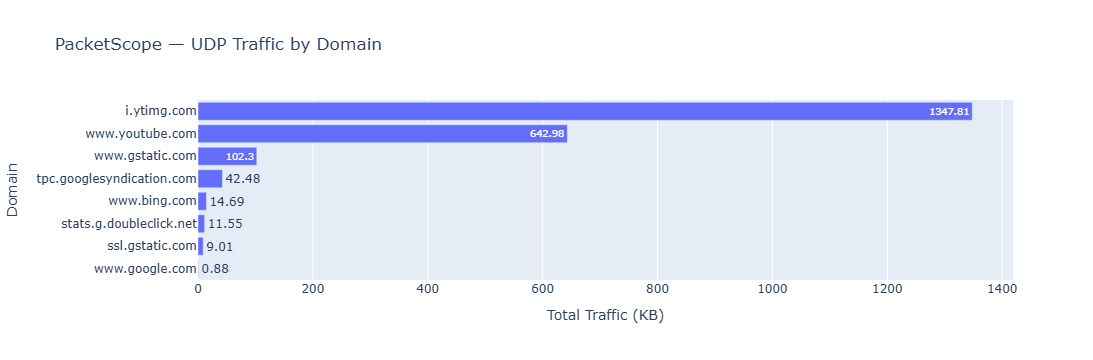

In [69]:
known_domains = quic_domain_summary[
    quic_domain_summary["Domain"] != "Domain not detected"
].copy()

fig = px.bar(
    known_domains.sort_values("Total_KB", ascending=False),
    x="Total_KB",
    y="Domain",
    orientation="h",
    title="PacketScope — UDP Traffic by Domain",
    labels={
        "Total_KB": "Total Traffic (KB)",
        "Domain": "Domain"
    },
    text="Total_KB"
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

In [70]:
udp_direction_summary = (
    quic_df.groupby(["Domain", "Direction"])
    .agg(
        Packets=("Packet Size", "count"),
        Total_Bytes=("Packet Size", "sum")
    )
    .reset_index()
)

udp_direction_summary["Total_KB"] = (
    udp_direction_summary["Total_Bytes"] / 1024
).round(2)

display(
    udp_direction_summary.sort_values(
        "Total_Bytes", ascending=False
    ).head(20)
)

,Domain,Direction,Packets,Total_Bytes,Total_KB
0,Domain not detected,Incoming,10420,13290157,12978.67
2,i.ytimg.com,Incoming,1061,1320192,1289.25
1,Domain not detected,Outgoing,5781,680102,664.16
16,www.youtube.com,Incoming,531,450228,439.68
17,www.youtube.com,Outgoing,441,208180,203.30
14,www.gstatic.com,Incoming,90,90282,88.17
3,i.ytimg.com,Outgoing,542,59966,58.56
8,tpc.googlesyndication.com,Incoming,34,32962,32.19
15,www.gstatic.com,Outgoing,64,14476,14.14
9,tpc.googlesyndication.com,Outgoing,25,10533,10.29


In [71]:
display(udp_direction_summary.head(20))

,Domain,Direction,Packets,Total_Bytes,Total_KB
0,Domain not detected,Incoming,10420,13290157,12978.67
1,Domain not detected,Outgoing,5781,680102,664.16
2,i.ytimg.com,Incoming,1061,1320192,1289.25
3,i.ytimg.com,Outgoing,542,59966,58.56
4,ssl.gstatic.com,Incoming,9,5178,5.06
5,ssl.gstatic.com,Outgoing,8,4051,3.96
6,stats.g.doubleclick.net,Incoming,18,6634,6.48
7,stats.g.doubleclick.net,Outgoing,15,5190,5.07
8,tpc.googlesyndication.com,Incoming,34,32962,32.19
9,tpc.googlesyndication.com,Outgoing,25,10533,10.29


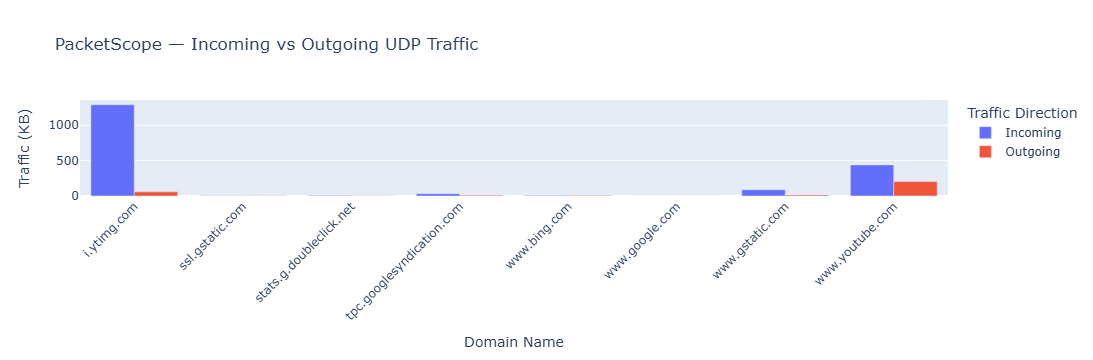

In [72]:
known_traffic = udp_direction_summary[
    udp_direction_summary["Domain"] != "Domain not detected"
].copy()

fig = px.bar(
    known_traffic,
    x="Domain",
    y="Total_KB",
    color="Direction",
    barmode="group",
    title="PacketScope — Incoming vs Outgoing UDP Traffic",
    labels={
        "Domain": "Domain Name",
        "Total_KB": "Traffic (KB)",
        "Direction": "Traffic Direction"
    }
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

In [73]:
protocol_comparison = pd.DataFrame({
    "Protocol": ["TCP", "DNS (UDP 53)", "UDP 443 (QUIC candidate)"],
    "Packets": [
        sum(TCP in p for p in captured),
        sum(UDP in p and (p[UDP].sport == 53 or p[UDP].dport == 53)
            for p in captured),
        len(quic_packets)
    ]
})

display(protocol_comparison)

,Protocol,Packets
0,TCP,30651
1,DNS (UDP 53),1115
2,UDP 443 (QUIC candidate),19108


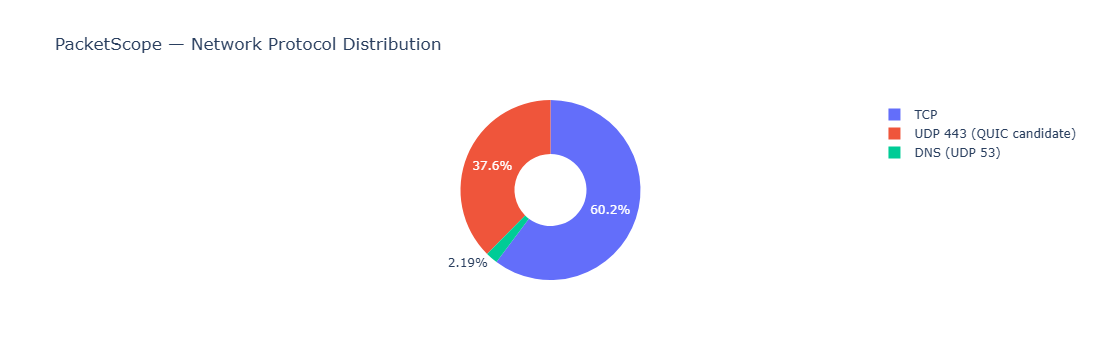

In [74]:
fig = px.pie(
    protocol_comparison,
    names="Protocol",
    values="Packets",
    title="PacketScope — Network Protocol Distribution",
    hole=0.4
)

fig.show()

In [75]:
destination_records = []

for packet in captured:
    if TCP not in packet and UDP not in packet:
        continue

    if IP in packet:
        src, dst = packet[IP].src, packet[IP].dst
    elif IPv6 in packet:
        src, dst = packet[IPv6].src, packet[IPv6].dst
    else:
        continue

    if src in local_ips:
        remote_ip = dst
    elif dst in local_ips:
        remote_ip = src
    else:
        continue

    destination_records.append({
        "Remote IP": remote_ip,
        "Protocol": "TCP" if TCP in packet else "UDP",
        "Packet Size": len(packet)
    })

destination_df = pd.DataFrame(destination_records)

destination_summary = (
    destination_df.groupby("Remote IP")
    .agg(
        Total_Packets=("Remote IP", "count"),
        Total_Bytes=("Packet Size", "sum"),
        Protocols=("Protocol",
                  lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("Total_Packets", ascending=False)
)

destination_summary["Domain"] = (
    destination_summary["Remote IP"]
    .map(ip_domain_map)
    .fillna("Domain not detected")
)

display(destination_summary.head(15))

,Remote IP,Total_Packets,Total_Bytes,Protocols,Domain
43,2404:6800:4013:807::13,11499,9976646,TCP,mail.google.com
21,2001:4860:482a:400::,2939,2624940,TCP,www.youtube.com
69,2606:50c0:8000::215,2381,2049977,TCP,github.githubassets.com
26,2400:1a00:cd11:a112::67d3:9568,1686,1167436,TCP,assets.msn.com
41,2404:6800:4013:800::61,1213,1030253,TCP,www.googletagmanager.com
10,163.47.150.180,1122,1002130,TCP,www.setopati.com
27,2400:1a00:cd11:a112::67d3:9573,1122,839522,TCP,ntp.msn.com
16,20.89.1.13,1091,949553,TCP,browser.events.data.msn.com
23,2400:1a00:8000:4::73,1071,163020,UDP,Domain not detected
57,2600:140f:7200:3c::17d4:c5,644,600651,TCP,www.bing.com


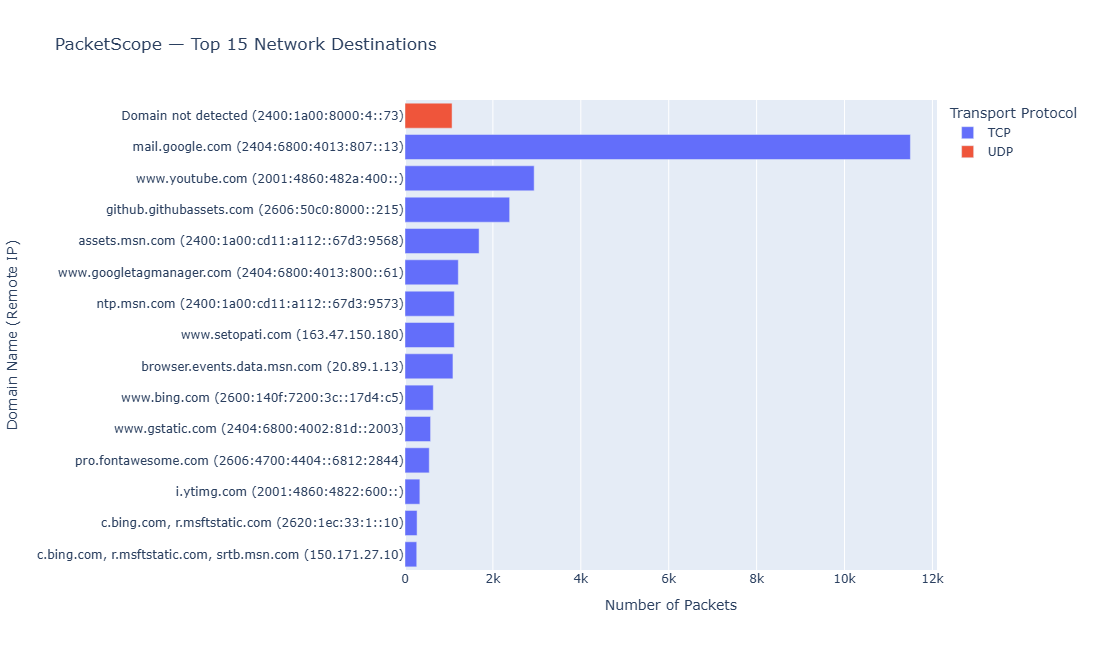

In [76]:
top_destinations = destination_summary.head(15).copy()

top_destinations["Destination"] = (
    top_destinations["Domain"] + " (" +
    top_destinations["Remote IP"] + ")"
)

fig = px.bar(
    top_destinations.sort_values("Total_Packets"),
    x="Total_Packets",
    y="Destination",
    orientation="h",
    color="Protocols",
    title="PacketScope — Top 15 Network Destinations",
    labels={
        "Total_Packets": "Number of Packets",
        "Destination": "Domain Name (Remote IP)",
        "Protocols": "Transport Protocol"
    },
    hover_data=["Total_Bytes", "Remote IP"]
)

fig.update_layout(height=650)
fig.show()

In [77]:
from scapy.all import sniff

timeline_packets = sniff(
    iface=wifi,
    timeout=60,
    store=True
)

print("Captured packets:", len(timeline_packets))

Captured packets: 689


In [78]:
from datetime import datetime
import pandas as pd

timeline_records = []

for packet in timeline_packets:
    if IP in packet:
        src = packet[IP].src
        dst = packet[IP].dst
    elif IPv6 in packet:
        src = packet[IPv6].src
        dst = packet[IPv6].dst
    else:
        continue

    if src in local_ips:
        direction = "Outgoing"
    elif dst in local_ips:
        direction = "Incoming"
    else:
        continue

    timeline_records.append({
        "Time": datetime.fromtimestamp(float(packet.time)),
        "Direction": direction,
        "Packet Size": len(packet)
    })

timeline_df = pd.DataFrame(timeline_records)

timeline_df.head()

,Time,Direction,Packet Size
0,2026-11-03 17:49:19.756087,Outgoing,91
1,2026-11-03 17:49:19.823686,Incoming,153
2,2026-11-03 17:49:19.824552,Outgoing,89
3,2026-11-03 17:49:19.833593,Incoming,90
4,2026-11-03 17:49:19.878525,Incoming,101


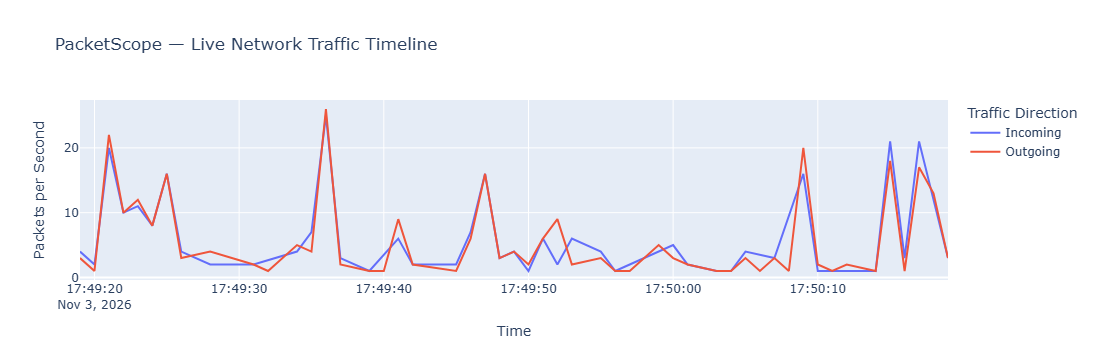

In [79]:
timeline_df["Second"] = timeline_df["Time"].dt.floor("s")

traffic_timeline = (
    timeline_df.groupby(["Second", "Direction"])
    .size()
    .reset_index(name="Packets")
)

fig = px.line(
    traffic_timeline,
    x="Second",
    y="Packets",
    color="Direction",
    title="PacketScope — Live Network Traffic Timeline",
    labels={
        "Second": "Time",
        "Packets": "Packets per Second",
        "Direction": "Traffic Direction"
    }
)

fig.show()

In [80]:
traffic_stats = {
    "Total Packets": len(timeline_df),
    "Incoming Packets": (timeline_df["Direction"] == "Incoming").sum(),
    "Outgoing Packets": (timeline_df["Direction"] == "Outgoing").sum(),
    "Incoming Traffic (KB)": round(
        timeline_df.loc[
            timeline_df["Direction"] == "Incoming",
            "Packet Size"
        ].sum() / 1024, 2
    ),
    "Outgoing Traffic (KB)": round(
        timeline_df.loc[
            timeline_df["Direction"] == "Outgoing",
            "Packet Size"
        ].sum() / 1024, 2
    ),
    "Average Packet Size (Bytes)": round(
        timeline_df["Packet Size"].mean(), 2
    ),
    "Largest Packet (Bytes)": timeline_df["Packet Size"].max()
}

display(pd.DataFrame(
    traffic_stats.items(),
    columns=["Metric", "Value"]
))

,Metric,Value
0,Total Packets,567.00
1,Incoming Packets,283.00
2,Outgoing Packets,284.00
3,Incoming Traffic (KB),69.61
4,Outgoing Traffic (KB),111.59
5,Average Packet Size (Bytes),327.25
6,Largest Packet (Bytes),1518.00
